# Data Quality Analysis: OpenAQ & Open-Meteo

Shared configuration: `ingest/vn_pipeline.toml`. Run the CLI backfill first; the notebook reads the resulting cache and never initiates a remote fetch. Strict manifest verification is the default. Paths and explicit legacy-audit mode can be set with `VN_PIPELINE_RAW_DIR`, `VN_PIPELINE_CONFIG`, `VN_PIPELINE_ALLOW_LEGACY_CACHE=1`. See `docs/ingest_setup_vn.md`.

Figures and metrics describe the selected snapshot. Legacy outputs, when explicitly requested, do not verify source/model provenance. Samples are reconstructed in memory. Internal gaps and boundary gaps follow the shared configuration.

**Primary handoff sample:** `data/sample/openaq_pm25_hanoi_hcmc.csv` and `data/sample/openmeteo_weather_hanoi_hcmc.csv`. These CSVs belong to the 2026-11-16 backfill and replace the older samples. Samples below are reconstructed from the configured raw snapshot.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ingest.config import load_config  # noqa: E402
from ingest.openaq_fetcher import (  # noqa: E402
    classify_station_lifecycle,
    compute_completeness_and_gaps,
)
from ingest.verify_vn_data import (  # noqa: E402
    build_summary_and_samples,
    load_or_fetch_vn_datasets,
    select_usable_station_ids,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.titleweight"] = "bold"

# Default: strict provenance and the same TOML as the CLI.
CONFIG_PATH = Path(
    os.environ.get("VN_PIPELINE_CONFIG", str(PROJECT_ROOT / "ingest/vn_pipeline.toml"))
)
config = load_config(CONFIG_PATH)
RAW_DIR = Path(os.environ.get("VN_PIPELINE_RAW_DIR", str(config.path("raw_dir"))))
ALLOW_LEGACY_CACHE = os.environ.get("VN_PIPELINE_ALLOW_LEGACY_CACHE", "0") == "1"
if not all(
    (RAW_DIR / name).is_file()
    for name in (
        "stations_hn_hcmc_all_62.csv",
        "openaq_pm25_full_2yr.csv",
        "openmeteo_weather_usable_stations_2yr.csv",
    )
):
    raise FileNotFoundError(
        "Raw cache missing. Run the documented CLI backfill before opening this notebook."
    )
WINDOW_START_UTC, WINDOW_END_UTC = config.window_start_utc, config.window_end_utc
SAMPLE_START_UTC, SAMPLE_END_UTC = config.sample_start_utc, config.sample_end_utc
df_stations_all, df_pm25_raw, df_wx_raw = load_or_fetch_vn_datasets(
    raw_dir=RAW_DIR,
    write_outputs=False,
    allow_legacy_cache=ALLOW_LEGACY_CACHE,
    config=config,
)
print("Config:", config.provenance())
print("Raw directory:", RAW_DIR, "Legacy audit:", ALLOW_LEGACY_CACHE)
df_pm25_raw["event_time_dt"] = pd.to_datetime(df_pm25_raw["event_time"], utc=True)
df_wx_raw["event_time_dt"] = pd.to_datetime(df_wx_raw["event_time"], utc=True)

df_lifecycle = classify_station_lifecycle(
    df_stations_all,
    df_pm25_raw,
    window_start_utc=WINDOW_START_UTC,
    window_end_utc=WINDOW_END_UTC,
    alive_cutoff_utc=config.alive_cutoff_utc,
)
display(df_lifecycle)
EXPECTED_WINDOW_HOURS = int(
    (pd.Timestamp(WINDOW_END_UTC) - pd.Timestamp(WINDOW_START_UTC)) / pd.Timedelta(hours=1)
)

Weather cache includes missing values; retained for quality reporting


Config: {'window_start_utc': '2024-11-14T00:00:00Z', 'window_end_utc': '2026-11-14T00:00:00Z', 'alive_cutoff_utc': '2026-11-01T00:00:00Z', 'sample_start_utc': '2025-11-15T00:00:00Z', 'sample_end_utc': '2025-11-22T00:00:00Z', 'max_missing_2yr_pct': 60.0, 'max_gt500_count': 0, 'include_boundary_gaps': False, 'weather_model': 'era5'}
Raw directory: /home/goncos/Projects/Nhom4-HKDN_2026-2027/data/raw/verified_2026-11-16 Legacy audit: False


city,lifecycle_status,HCMC,Hanoi,Total
0,not_fetched (activity unknown),0,0,0
1,zero_valid_hours (records present),1,0,1
2,inactive (no valid observations since cutoff),12,36,48
3,active (valid observations since cutoff),1,5,6
4,no_data_in_window (fetch completed),5,2,7
5,fetch_failed (activity unknown),0,0,0


## 2. Hourly completeness and outage gaps (configured UTC window)

In [2]:
df_completeness, df_all_gaps = compute_completeness_and_gaps(
    df_pm25_raw,
    **config.metrics_kwargs(),
)
USABLE_STATION_IDS = select_usable_station_ids(df_completeness)

# Display the stations active through Nov 2026 plus key historical reference stations
focus_ids = USABLE_STATION_IDS + [4946811, 2161306, 7441, 7440]
df_focus = df_completeness[
    df_completeness["station_id"].isin(focus_ids) | (df_completeness["valid_hours"] >= 4000)
].copy()

summary_cols = [
    "city",
    "station_id",
    "sensor_id",
    "station_name",
    "is_monitor",
    "alive_nov2026",
    "usable_demo",
    "valid_hours",
    "nan_rows",
    "completeness_2yr_pct",
    "missing_2yr_pct",
    "active_span_h",
    "missing_in_active_pct",
    "num_gaps",
    "num_gaps_ge_24h",
    "max_gap_hours",
    "gt500_count",
    "first_valid_utc",
    "last_valid_utc",
]
display(df_focus[summary_cols])

# Top 10 longest continuous outage gaps (>= 24h) across usable stations
display(
    df_all_gaps[
        df_all_gaps["station_id"].isin(USABLE_STATION_IDS) & (df_all_gaps["gap_hours"] >= 24)
    ].head(10)
)

,city,station_id,sensor_id,station_name,is_monitor,alive_nov2026,usable_demo,valid_hours,nan_rows,completeness_2yr_pct,missing_2yr_pct,active_span_h,missing_in_active_pct,num_gaps,num_gaps_ge_24h,max_gap_hours,gt500_count,first_valid_utc,last_valid_utc
0,HCMC,3276359,11357424,CMT8,False,True,True,16048,0,91.60,8.40,17390,7.72,62,5,690,0,2024-11-19T10:00:00Z,2026-11-13T23:00:00Z
1,Hanoi,4946812,13502151,Công viên Nhân Chính - Khuất Duy Tiến,True,True,True,11531,0,65.82,34.18,11961,3.60,63,4,86,0,2025-07-03T15:00:00Z,2026-11-13T23:00:00Z
2,Hanoi,2161292,7772032,"Số 46, phố Lưu Quang Vũ",True,True,True,11392,57,65.02,34.98,17498,34.90,228,61,859,0,2024-11-14T00:00:00Z,2026-11-13T01:00:00Z
3,Hanoi,4946813,13502154,Số 1 đường Giải Phóng - phường Bạch Mai - ĐHBK,True,True,True,11098,0,63.34,36.66,11961,7.22,189,8,136,0,2025-07-03T15:00:00Z,2026-11-13T23:00:00Z
4,Hanoi,6123215,14581375,Dragon,False,True,True,8646,0,49.35,50.65,8899,2.84,42,2,119,0,2025-11-08T05:00:00Z,2026-11-13T23:00:00Z
5,Hanoi,4946811,13502150,556 Nguyễn Văn Cừ,True,False,False,7829,0,44.69,55.31,9044,13.43,134,4,625,0,2025-07-03T15:00:00Z,2026-07-15T10:00:00Z
6,Hanoi,2161296,7772040,Đào Duy Từ,True,False,False,4845,0,27.65,72.35,4995,3.00,12,2,58,0,2024-11-14T00:00:00Z,2025-06-10T02:00:00Z
7,Hanoi,2161290,7772012,An Khánh,True,False,False,4836,0,27.60,72.40,4995,3.18,15,2,58,0,2024-11-14T00:00:00Z,2025-06-10T02:00:00Z
8,Hanoi,2161320,7772059,Vân Hà,True,False,False,4775,0,27.25,72.75,4995,4.40,11,3,60,0,2024-11-14T00:00:00Z,2025-06-10T02:00:00Z
9,Hanoi,2161306,7772087,Minh Khai - Bắc Từ Liêm,True,True,False,4304,8,24.57,75.43,17512,75.42,272,67,3849,13,2024-11-14T01:00:00Z,2026-11-13T16:00:00Z


,city,station_id,station_name,gap_start_utc,gap_end_utc,gap_hours,gap_days
2,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2025-11-21T13:00:00Z,2025-12-27T07:00:00Z,859,35.8
4,HCMC,3276359,CMT8,2025-01-13T23:00:00Z,2025-02-11T16:00:00Z,690,28.8
10,HCMC,3276359,CMT8,2025-06-07T06:00:00Z,2025-06-23T14:00:00Z,393,16.4
11,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2025-12-28T03:00:00Z,2026-01-13T07:00:00Z,389,16.2
18,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2026-04-24T01:00:00Z,2026-05-03T19:00:00Z,235,9.8
24,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2025-07-28T19:00:00Z,2025-08-04T03:00:00Z,153,6.4
25,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2026-08-12T01:00:00Z,2026-08-18T04:00:00Z,148,6.2
26,Hanoi,4946813,Số 1 đường Giải Phóng - phường Bạch Mai - ĐHBK,2025-12-25T17:00:00Z,2025-12-31T08:00:00Z,136,5.7
27,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",2026-08-06T01:00:00Z,2026-08-11T12:00:00Z,132,5.5
28,Hanoi,6123215,Dragon,2026-07-01T01:00:00Z,2026-07-05T23:00:00Z,119,5.0


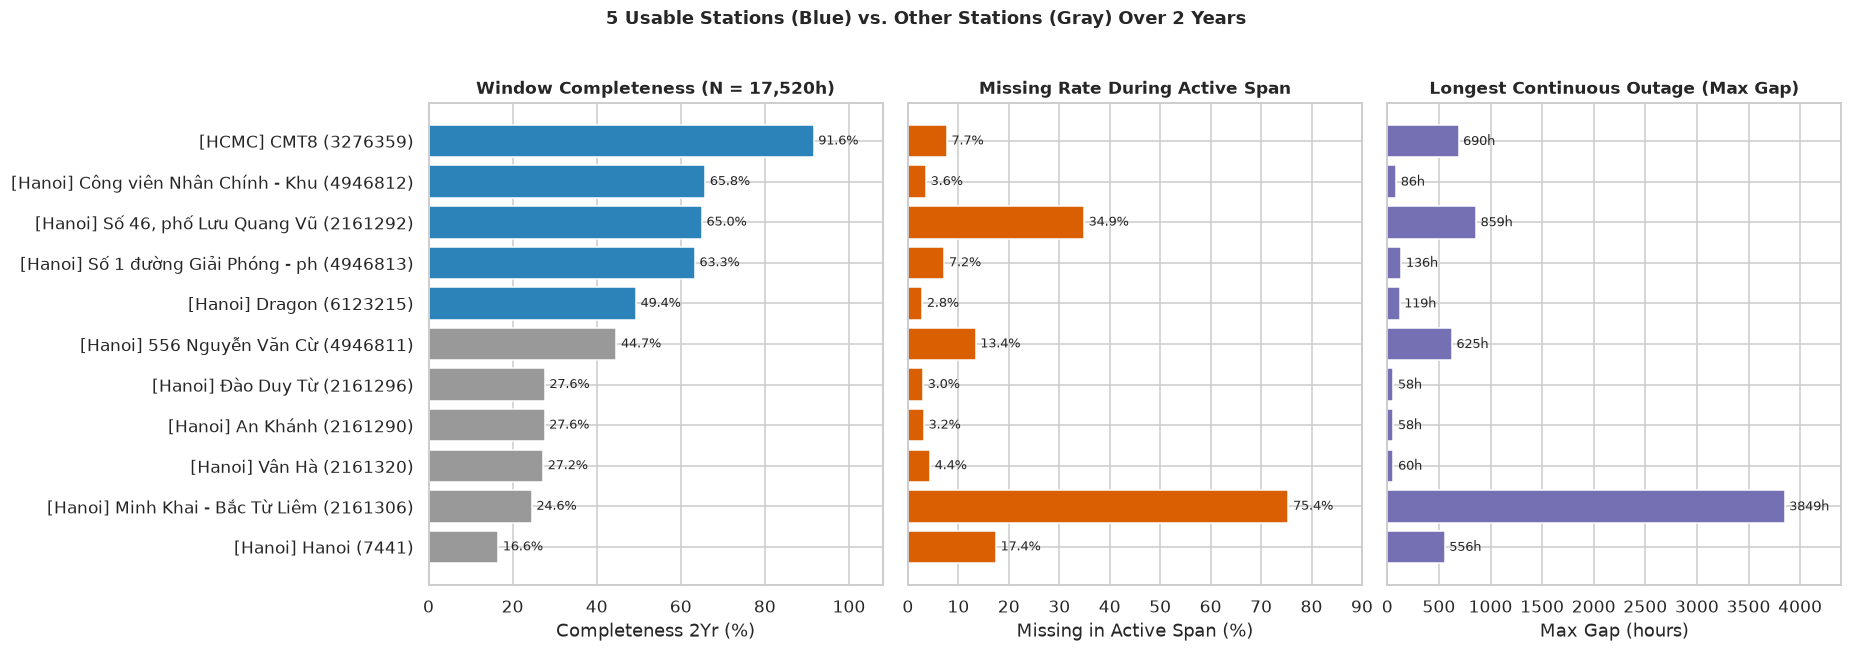

In [3]:
# Figure 1: 2-Year Completeness vs. Missing Rate in Active Span & Max Outage Gap
df_plot = df_focus[df_focus["valid_hours"] > 0].sort_values("valid_hours", ascending=True).copy()
df_plot["label"] = (
    "["
    + df_plot["city"]
    + "] "
    + df_plot["station_name"].str.slice(0, 26)
    + " ("
    + df_plot["station_id"].astype(str)
    + ")"
)
bar_colors = ["#2b83ba" if u else "#999999" for u in df_plot["usable_demo"]]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), sharey=True)

b0 = axes[0].barh(df_plot["label"], df_plot["completeness_2yr_pct"], color=bar_colors)
axes[0].set_title(f"Window Completeness (N = {EXPECTED_WINDOW_HOURS:,}h)")
axes[0].set_xlabel("Completeness 2Yr (%)")
axes[0].set_xlim(0, 108)
axes[0].bar_label(b0, fmt="%.1f%%", padding=3, fontsize=8.5)

b1 = axes[1].barh(df_plot["label"], df_plot["missing_in_active_pct"], color="#d95f02")
axes[1].set_title("Missing Rate During Active Span")
axes[1].set_xlabel("Missing in Active Span (%)")
axes[1].set_xlim(0, 90)
axes[1].bar_label(b1, fmt="%.1f%%", padding=3, fontsize=8.5)

b2 = axes[2].barh(df_plot["label"], df_plot["max_gap_hours"], color="#7570b3")
axes[2].set_title("Longest Continuous Outage (Max Gap)")
axes[2].set_xlabel("Max Gap (hours)")
axes[2].set_xlim(0, 4400)
axes[2].bar_label(b2, fmt="%dh", padding=3, fontsize=8.5)

plt.suptitle(
    f"{len(USABLE_STATION_IDS)} Usable Stations (Blue) vs. Other Stations (Gray) Over 2 Years",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

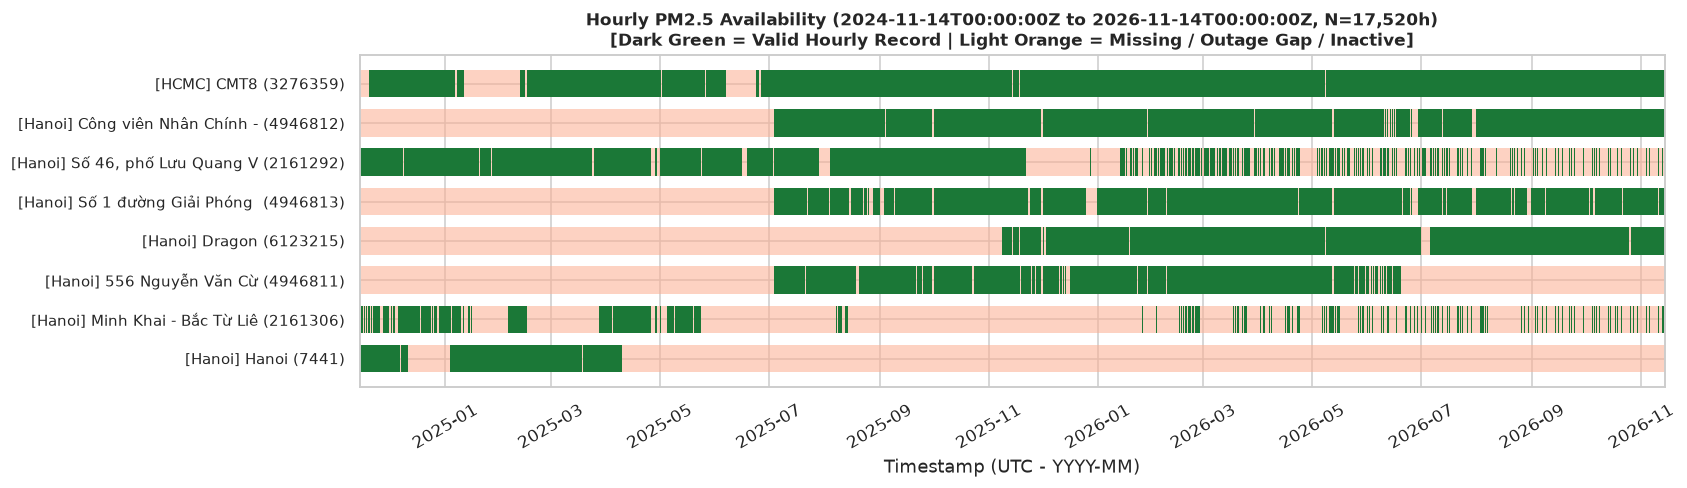

In [4]:
# Figure 2: 2-Year Hourly Availability Barcode Timeline Computed Directly from df_pm25_raw
timeline_ids = [
    sid
    for sid in USABLE_STATION_IDS + [4946811, 2161306, 7441]
    if sid in set(df_completeness.station_id)
]
w_start_ts = pd.Timestamp(WINDOW_START_UTC)
w_end_ts = pd.Timestamp(WINDOW_END_UTC)
full_2yr_index = pd.date_range(
    start=w_start_ts, end=w_end_ts - pd.Timedelta(hours=1), freq="1h", tz="UTC"
)

fig, ax = plt.subplots(figsize=(15.5, 4.6))
labels_y = []

for y_idx, st_id in enumerate(reversed(timeline_ids)):
    st_row = df_completeness[df_completeness["station_id"] == st_id].iloc[0]
    labels_y.append(f"[{st_row['city']}] {st_row['station_name'][:22]} ({st_id})")

    grp = df_pm25_raw[
        (df_pm25_raw["station_id"] == st_id)
        & np.isfinite(df_pm25_raw["pm25_ug_m3"])
        & (df_pm25_raw["pm25_ug_m3"] >= 0)
    ]
    ax.broken_barh(
        [(mdates.date2num(w_start_ts), mdates.date2num(w_end_ts) - mdates.date2num(w_start_ts))],
        (y_idx - 0.35, 0.7),
        facecolors="#fcae91",
        edgecolors="none",
        alpha=0.55,
    )
    s_present = pd.Series(False, index=full_2yr_index)
    s_present.loc[s_present.index.intersection(grp["event_time_dt"])] = True
    vals = s_present.to_numpy()
    padded = np.concatenate(([False], vals, [False]))
    starts = np.where(padded[1:] & ~padded[:-1])[0]
    ends = np.where(~padded[1:] & padded[:-1])[0]
    segments = [
        (
            mdates.date2num(full_2yr_index[s_i]),
            mdates.date2num(full_2yr_index[e_i - 1] + pd.Timedelta(hours=1))
            - mdates.date2num(full_2yr_index[s_i]),
        )
        for s_i, e_i in zip(starts, ends)
    ]
    ax.broken_barh(segments, (y_idx - 0.35, 0.7), facecolors="#1b7837", edgecolors="none")

ax.set_yticks(range(len(timeline_ids)))
ax.set_yticklabels(labels_y, fontsize=9.5)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_xlim(mdates.date2num(w_start_ts), mdates.date2num(w_end_ts))
ax.set_title(
    f"Hourly PM2.5 Availability ({WINDOW_START_UTC} to {WINDOW_END_UTC}, N={EXPECTED_WINDOW_HOURS:,}h)\n"
    "[Dark Green = Valid Hourly Record | Light Orange = Missing / Outage Gap / Inactive]"
)
ax.set_xlabel("Timestamp (UTC - YYYY-MM)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Open-Meteo 2-Year Completeness & 1-Week Sample Verification (`data/sample/`)

In [5]:
_, _, df_pm25_sample, df_wx_sample = build_summary_and_samples(
    df_pm25_raw, df_wx_raw, write_outputs=False, config=config
)
df_pm25_sample["event_time_dt"] = pd.to_datetime(df_pm25_sample["event_time"], utc=True)
df_wx_sample["event_time_dt"] = pd.to_datetime(df_wx_sample["event_time"], utc=True)

WX_COLS = [
    "station_id",
    "event_time",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]
df_merged_sample = pd.merge(
    df_pm25_sample,
    df_wx_sample[WX_COLS],
    on=["station_id", "event_time"],
    how="left",
    validate="one_to_one",
    indicator=True,
)
df_pm25_usable_2yr = df_pm25_raw[df_pm25_raw["station_id"].isin(USABLE_STATION_IDS)]
df_merged_2yr = pd.merge(
    df_pm25_usable_2yr[["station_id", "event_time", "pm25_ug_m3"]],
    df_wx_raw[WX_COLS],
    on=["station_id", "event_time"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

# 3.1. Audit table across 2-Year Raw and 1-Week Sample datasets
df_audit = pd.DataFrame(
    [
        {
            "dataset": "OpenAQ PM2.5 Full Window (JOIN metric: usable stations only)",
            "rows": len(df_pm25_raw),
            "stations": df_pm25_raw["station_id"].nunique(),
            "dup_(station_id,event_time)": int(
                df_pm25_raw.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(df_pm25_raw["pm25_ug_m3"].isna().sum()),
            "neg_count": int((df_pm25_raw["pm25_ug_m3"] < 0).sum()),
            "weather_join_match_pct": round(df_merged_2yr["_merge"].eq("both").mean() * 100, 2),
        },
        {
            "dataset": "Open-Meteo Weather Full 2Yr",
            "rows": len(df_wx_raw),
            "stations": df_wx_raw["station_id"].nunique(),
            "dup_(station_id,event_time)": int(
                df_wx_raw.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(df_wx_raw[WX_COLS[2:]].isna().sum().sum()),
            "neg_count": int((df_wx_raw["wind_speed_m_s"] < 0).sum()),
            "weather_join_match_pct": np.nan,  # Not applicable to the weather side
        },
        {
            "dataset": "OpenAQ PM2.5 1-Week Sample (data/sample)",
            "rows": len(df_pm25_sample),
            "stations": df_pm25_sample["station_id"].nunique(),
            "dup_(station_id,event_time)": int(
                df_pm25_sample.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(df_pm25_sample["pm25_ug_m3"].isna().sum()),
            "neg_count": int((df_pm25_sample["pm25_ug_m3"] < 0).sum()),
            "weather_join_match_pct": round(df_merged_sample["_merge"].eq("both").mean() * 100, 2),
        },
        {
            "dataset": "Open-Meteo Weather 1-Week Sample (data/sample)",
            "rows": len(df_wx_sample),
            "stations": df_wx_sample["station_id"].nunique(),
            "dup_(station_id,event_time)": int(
                df_wx_sample.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(df_wx_sample[WX_COLS[2:]].isna().sum().sum()),
            "neg_count": int((df_wx_sample["wind_speed_m_s"] < 0).sum()),
            "weather_join_match_pct": np.nan,  # Not applicable to the weather side
        },
    ]
)
display(df_audit)

# 3.2. Per-station completeness in the 1-week sample (168 expected hours/station)
EXPECTED_SAMPLE_HOURS = int(
    (pd.Timestamp(SAMPLE_END_UTC) - pd.Timestamp(SAMPLE_START_UTC)) / pd.Timedelta(hours=1)
)
sample_rows = []
for (city, st_id, st_name), grp in df_merged_sample.groupby(
    ["city", "station_id", "station_name"], sort=False
):
    wx_grp = df_wx_sample[df_wx_sample["station_id"] == st_id]
    sample_rows.append(
        {
            "city": city,
            "station_id": int(st_id),
            "station_name": st_name,
            "pm25_valid_h": len(grp),
            "pm25_missing_h": EXPECTED_SAMPLE_HOURS - len(grp),
            "pm25_completeness_pct": round(len(grp) / EXPECTED_SAMPLE_HOURS * 100, 2),
            "wx_valid_h": int(wx_grp[WX_COLS[2:]].notna().all(axis=1).sum()),
            "pm25_mean": round(grp["pm25_ug_m3"].mean(), 2),
            "temp_mean_c": round(wx_grp["temperature_c"].mean(), 2),
            "rh_mean_pct": round(wx_grp["relative_humidity_pct"].mean(), 2),
            "wind_mean_m_s": round(wx_grp["wind_speed_m_s"].mean(), 2),
        }
    )
display(pd.DataFrame(sample_rows))

,dataset,rows,stations,"dup_(station_id,event_time)",nan_count,neg_count,weather_join_match_pct
0,OpenAQ PM2.5 Full Window (JOIN metric: usable ...,112673,36,0,3302,0,100.0
1,Open-Meteo Weather Full 2Yr,87600,5,0,1800,0,NaN
2,OpenAQ PM2.5 1-Week Sample (data/sample),815,5,0,0,0,100.0
3,Open-Meteo Weather 1-Week Sample (data/sample),840,5,0,0,0,NaN


,city,station_id,station_name,pm25_valid_h,pm25_missing_h,pm25_completeness_pct,wx_valid_h,pm25_mean,temp_mean_c,rh_mean_pct,wind_mean_m_s
0,HCMC,3276359,CMT8,164,4,97.62,168,35.05,26.59,83.52,1.68
1,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",157,11,93.45,168,32.01,19.81,76.58,2.48
2,Hanoi,4946812,Công viên Nhân Chính - Khuất Duy Tiến,168,0,100.00,168,40.55,19.86,76.59,2.48
3,Hanoi,4946813,Số 1 đường Giải Phóng - phường Bạch Mai - ĐHBK,162,6,96.43,168,48.85,19.81,76.58,2.48
4,Hanoi,6123215,Dragon,164,4,97.62,168,50.75,20.10,72.22,2.92


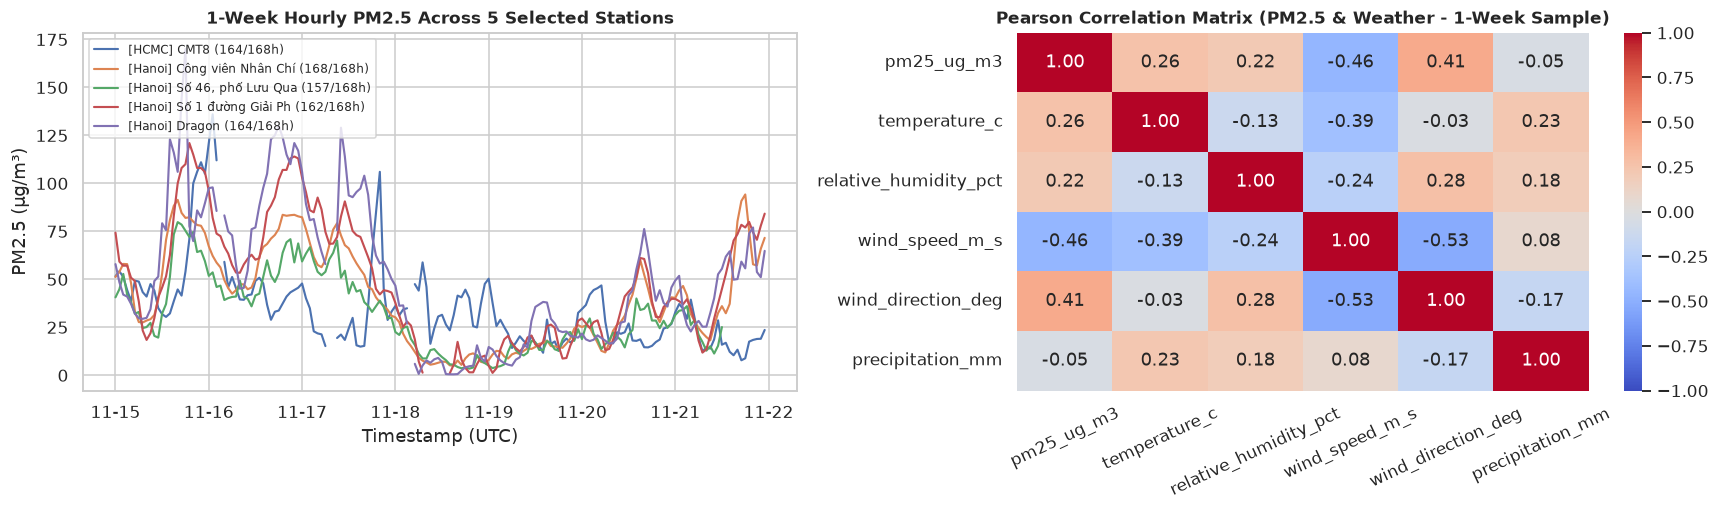

In [6]:
# Figure 3: 1-Week Hourly PM2.5 Series & Weather Correlation on data/sample/
full_sample_index = pd.date_range(
    start=pd.Timestamp(SAMPLE_START_UTC),
    end=pd.Timestamp(SAMPLE_END_UTC) - pd.Timedelta(hours=1),
    freq="1h",
    tz="UTC",
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

for st_id in USABLE_STATION_IDS:
    st_sub = df_pm25_sample[df_pm25_sample["station_id"] == st_id]
    if st_sub.empty:
        continue
    st_name = st_sub["station_name"].iloc[0][:18]
    city = st_sub["city"].iloc[0]
    series = st_sub.set_index("event_time_dt")["pm25_ug_m3"].reindex(full_sample_index)
    axes[0].plot(
        series.index, series.values, label=f"[{city}] {st_name} ({len(st_sub)}/168h)", linewidth=1.4
    )

axes[0].set_title(f"1-Week Hourly PM2.5 Across {len(USABLE_STATION_IDS)} Selected Stations")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_xlabel("Timestamp (UTC)")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].legend(fontsize=8, loc="upper left")

corr_cols = [
    "pm25_ug_m3",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]
sns.heatmap(
    df_merged_sample[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Pearson Correlation Matrix (PM2.5 & Weather - 1-Week Sample)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 4. Beijing Multi-Site: one-week contract sample

The mentor selected Beijing Multi-Site for experiments. This section rebuilds the handoff sample from the official UCI archive, verifies the seven shared columns, and reports missing values. It does not define experiment splits or assess the full dataset. Run `python -m ingest.beijing_fetcher` first with a new output/metadata path as documented in `docs/beijing_multisite.md`.

**Timezone assumption:** source calendar fields are local Beijing time (`Asia/Shanghai`); the UCI page does not explicitly specify timezone. Humidity is a derived liquid-water Magnus approximation from TEMP/DEWP. Missing values remain missing; wind bearings represent the direction from which wind blows.


In [7]:
from ingest.beijing_fetcher import FEATURE_COLUMNS, build_beijing_sample
from ingest.feature_schema import build_vietnam_features, normalize_feature_table

BEIJING_ARCHIVE = Path(
    os.environ.get(
        "BEIJING_SOURCE_ARCHIVE", str(PROJECT_ROOT / "data/raw/beijing_multisite/uci_501.zip")
    )
)
if not BEIJING_ARCHIVE.is_file():
    raise FileNotFoundError("Run Beijing ingestion first; see docs/beijing_multisite.md")
df_beijing, beijing_metadata = build_beijing_sample(BEIJING_ARCHIVE)
df_beijing_handoff = pd.read_csv(PROJECT_ROOT / "data/sample/beijing_multisite_features.csv")
pd.testing.assert_frame_equal(
    df_beijing, df_beijing_handoff, check_dtype=False, atol=1e-8, rtol=1e-8
)
assert list(df_beijing.columns) == FEATURE_COLUMNS
assert not df_beijing.duplicated(["station_id", "event_time"]).any()
print("Beijing source DOI:", beijing_metadata["doi"])
print("Source archive SHA-256:", beijing_metadata["source_archive_sha256"])
print("Source timezone assumption:", beijing_metadata["source_timezone"])
print("UTC sample:", beijing_metadata["sample_start_utc"], beijing_metadata["sample_end_utc"])
print("Rows:", len(df_beijing), "Missing cells:", beijing_metadata["missing_cells"])
display(
    df_beijing.groupby("station_id").agg(
        rows=("event_time", "size"),
        pm25_missing=("pm25_ug_m3", lambda values: int(values.isna().sum())),
        humidity_missing=("relative_humidity_pct", lambda values: int(values.isna().sum())),
        direction_missing=("wind_direction_deg", lambda values: int(values.isna().sum())),
    )
)
display(df_beijing.head())
# Both sources enter downstream processing through the same typed contract.

vn_features = build_vietnam_features(df_pm25_sample, df_wx_sample)
beijing_features = normalize_feature_table(df_beijing_handoff)
assert list(vn_features.columns) == list(beijing_features.columns) == FEATURE_COLUMNS
assert vn_features.dtypes.astype(str).equals(beijing_features.dtypes.astype(str))
print("Shared downstream schema verified:")
display(vn_features.dtypes.astype(str).rename("dtype").to_frame())

Beijing source DOI: 10.24432/C5RK5G
Source archive SHA-256: b04da438b2f331ac0ffd45aebdfec0d20d2367feb5f6948c4b1f7ce1191e33c4
Source timezone assumption: Asia/Shanghai
UTC sample: 2015-11-15T00:00:00+00:00 2015-11-22T00:00:00+00:00
Rows: 2016 Missing cells: {'station_id': 0, 'event_time': 0, 'pm25_ug_m3': 26, 'temperature_c': 0, 'relative_humidity_pct': 0, 'wind_speed_m_s': 0, 'wind_direction_deg': 14}


,rows,pm25_missing,humidity_missing,direction_missing
station_id,,,,
beijing_Aotizhongxin,168,1,0,0
beijing_Changping,168,1,0,1
beijing_Dingling,168,1,0,1
beijing_Dongsi,168,1,0,0
beijing_Guanyuan,168,2,0,0
beijing_Gucheng,168,1,0,0
beijing_Huairou,168,3,0,8
beijing_Nongzhanguan,168,5,0,0
beijing_Shunyi,168,1,0,4


,station_id,event_time,pm25_ug_m3,temperature_c,relative_humidity_pct,wind_speed_m_s,wind_direction_deg
0,beijing_Aotizhongxin,2015-11-15T00:00:00Z,210.0,4.8,99.304775,0.1,45.0
1,beijing_Aotizhongxin,2015-11-15T01:00:00Z,177.0,6.4,99.313637,0.4,22.5
2,beijing_Aotizhongxin,2015-11-15T02:00:00Z,176.0,8.9,80.911652,1.6,22.5
3,beijing_Aotizhongxin,2015-11-15T03:00:00Z,221.0,9.5,74.024899,0.8,315.0
4,beijing_Aotizhongxin,2015-11-15T04:00:00Z,225.0,11.2,67.012964,1.8,45.0


Shared downstream schema verified:


,dtype
station_id,string
event_time,"datetime64[us, UTC]"
pm25_ug_m3,float64
temperature_c,float64
relative_humidity_pct,float64
wind_speed_m_s,float64
wind_direction_deg,float64


## 5. Conclusion

The outputs were recomputed from the 2026-11-16 API backfill with strict manifest v2 verification and explicit ERA5 weather. Five stations meet the proposed demo screening rule; this rule is not yet mentor-approved. Current availability, calibration and streaming readiness require separate evidence.

Weather timestamps match PM2.5 keys, but 72 trailing hours per station contain missing values under the ERA5 archive delay policy. Do not treat key match as complete weather coverage. Preserve missing data and record gaps without cross-station imputation.

The team has agreed to use Beijing Multi-Site for experiments and Vietnam data for the demo. Beijing ingestion and the one-week contract sample are included and verified above; experiment splits and model evaluation remain outside this task. Choose Vietnam demo windows from available data and preserve missing intervals. See `docs/data_quality_report_vn.md`.
